# Clustering packets of WPT using k-means method
Here we use entropy, kurtosis and crest for k-means clustering and thresholding. The test data are generated by solving GA bubble model.

In [1]:
import sys
if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:
%matplotlib inline
sys.path.append("..")

import matplotlib.pyplot as plt
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import pandas as pd
from wavelet_transform.utils.save_plots import save_figure


import numpy as np
import wavelet_transform.utils.training_data as train
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.wpt.inverse_transform as inv
from wavelet_transform.utils.extensions import fft, to_dB, psd #, trim_data
from wavelet_transform.utils.machine_learning import train_k_means,fit_and_evaluate, assess_parameter
import wavelet_transform.utils.kmeans_results as results
from wavelet_transform.utils.preprocessing import preprocess
from wavelet_transform.utils.bubbledynamics import BubbleDynamics as BD


### Parameters

Specify parameters for synthetic data and wavelet transform. The parameters used for the paper are:

freq = 1.1 MHz

pac = 1 MPa, r_init = 1e-6 for transient

pac = 1 MPa, r_init = 20e-6 for stable

In [3]:
pac = 1e6  # the amplitude of the sine wave in Pa
frequency = 1.1 * 1e6  # insonation frequency (Hz)
R_init = 100e-6  # initial bubble radius in meters
period = 1 / frequency # the period of the acoustic wave at the fundamental frequency 
n_cycles = 10  # no. of cycles of the sine wave

parameters = {
    "time_delay": 0 * period,  # time delay, t1
    "pulse_width": 10*n_cycles * period,  # pulse width, W = 1 / Q
    "phase_initial": 0 * period,  # tau
    "phase_shift": 0, #np.pi / 4,  # phi
    "no_harmonics": 1,   # k
    "Rdot_init": 0,  # initial bubble's wall velocity in m/s
}

r_measure = 100 * 1e-6 # distance from the centre of bubble which radiated pressure (acoustic emission from bubble) is calculated over time

result_id = f"{R_init}_{frequency}_{pac}"


In [4]:
savefig_flag = True
font_dict={'family':'Serif','color':'black','size':12}

In [5]:
# Set sampling rate and noise std
sampling_rate = 500 * frequency
signal2noise = 20

In [6]:
import pywt
# pywt.wavelist(kind='discrete')

In [7]:
# Parameters for the wavelet transform
wavelet = "sym20"
levels = None  # set to None to use max-level transform
mode = "symmetric"
use_min_entropy = True
min_level = 5
freq_threshold = 1 #50e6/(sampling_rate / 2)  # the nodes with norm_freq_range above this threshold will not be kept

Family of fonts to use in plotly: https://blog.hubspot.com/website/web-safe-html-css-fonts

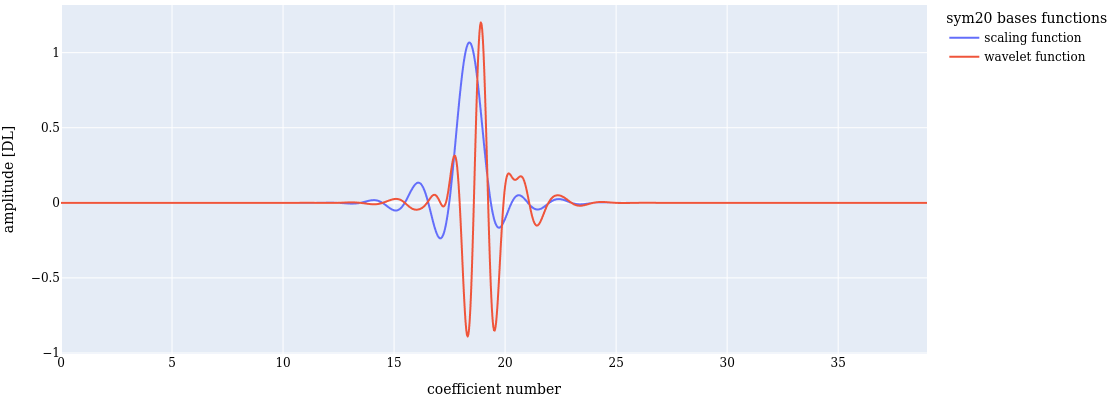

In [8]:
[phi, psi, x] = pywt.Wavelet(wavelet).wavefun(level=min_level)

wavelet_scal_df = pd.DataFrame(
    data={
        "x": x,
        "y": phi,
        "legend": "scaling function",
    }
)
wavelet_fun_df = pd.DataFrame(
    data={
        "x": x,
        "y": psi,
        "legend": "wavelet function",
    }
)
wavelet_df = pd.concat([wavelet_scal_df, wavelet_fun_df])

fig = px.line(wavelet_df,x="x", y="y", color="legend")

fig.update_layout(
    height=400,
    width=800,
    font=font_dict, 
    margin_l=5, margin_t=5, margin_b=5, margin_r=5,
    legend_title=wavelet+' bases functions',
    xaxis=dict(title="coefficient number"),
    yaxis=dict(title="amplitude [DL]"), #r"$\text{Relative radiated pressure } [p/p_0]$"),
)
fig.show()
if savefig_flag:
    save_figure(fig, wavelet+f"_bases functions_{result_id}")


### Generating acoustic emission data by solving Gilmore-Akulichev model

Generate the acoustic emission data and add measurement noise (assuming additive white Gaussian noise). Plot the data with its FFT. 

In [9]:
# BUBBLE DYNAMICS DATA
data, t_plot = train.get_data(
    R_init, frequency, pac, sampling_rate, n_cycles=n_cycles, r_measure=r_measure,
    return_time=True, **parameters
)

# Add noise
data = train.add_noise(data, signal2noise, display_std_noise=True)

# data, t_plot = trim_data(data, t_plot, (0.5e-6, 15e-6), return_time=True)

std_noise: 2.0554388562161234


In [10]:
# Normalise
data_processed = preprocess(data, window=False)

In [11]:
# Plot generated data
fft_lim = 10
fft_data, freq = fft(data_processed, sampling_rate, frequency)
psd_data, psd_freq = psd(data_processed, sampling_rate, frequency)

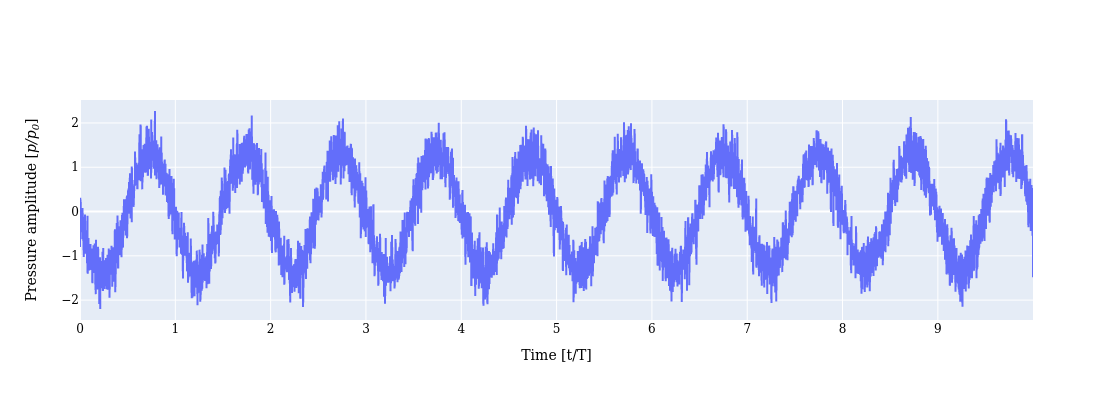

In [12]:
# plot sound wave and fft
fig = go.Figure()
fig.add_trace(
    go.Scatter(x=t_plot/period , y=data_processed, mode="lines", name="acoustic emission - GA model")
)


fig.update_layout(
    height=400,
    width=800,
    font=font_dict, 
    # margin_l=5, margin_t=5, margin_b=5, margin_r=5,
    xaxis1=dict(title="Time [t/T]"),
    yaxis1=dict(title="Pressure amplitude [<i>p/p<sub>0</sub></i>]"),
)
fig.show()
if savefig_flag:
    save_figure(fig, f"GA_pressure_{result_id}")

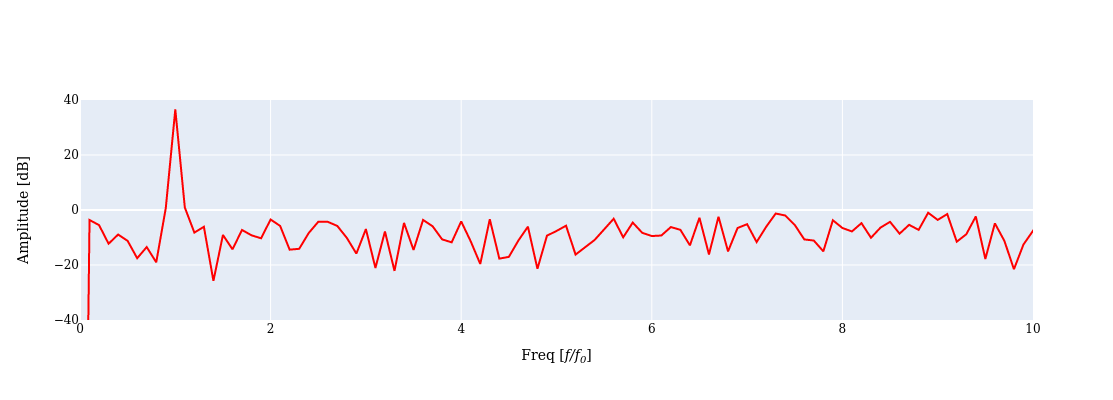

In [13]:
# plot sound wave and fft
fig = go.Figure()
fig.add_trace(
    go.Scatter(x=psd_freq, y=to_dB(psd_data), 
               mode="lines", name="fft - amp",line_color='red')
)

fig.update_layout(
    height=400,
    width=800,
    font=font_dict, 
    # margin_l=5, margin_t=5, margin_b=5, margin_r=5,
    xaxis1=dict(title="Freq [<i>f/f<sub>0</sub></i>]", range=[0, fft_lim]),
    yaxis1=dict(title="Amplitude [dB]",range=[-40,40]),
)
fig.show()
if savefig_flag:
    save_figure(fig, f"GA_pressure_spectrum_{result_id}")

# Wavelet transform

In [14]:
wpt_df, tr_obj = train.generate_training_data(
    data_processed, levels, wavelet, mode, 
    include_tr_obj=True, min_entropy=use_min_entropy,
    min_level=min_level, freq_threshold=freq_threshold
)

### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

In [15]:
# tr_obj.calc_frequencies(sampling_rate)
# plot.heisenberg(tr_obj, max(t_plot))

In [16]:
# nodes = tr_obj.get_leaf_nodes(order="freq")
# nodes_data = np.zeros((len(nodes), len(nodes[0].data)))
# for i, j in enumerate(range(len(nodes) - 1, -1, -1)):  # maybe reverse
#     node = nodes[j]
#     nodes_data[i, :] = np.abs(node.data)  # plot absolute values of wavelet coefficients
# nodes_data.shape

In [17]:
# from scipy import signal
# t_plot_ds = signal.decimate(t_plot, 16)[:nodes_data.shape[1]]


In [18]:
# import plotly.graph_objects as go
# fig = go.Figure()
# fig.add_trace(go.Heatmap(z=20*np.log10(nodes_data),
#                          x=np.linspace(0,t_plot[-1]*1e6,nodes_data.shape[1]) ,
#                          y=np.linspace(0,sampling_rate/2/1e6,nodes_data.shape[0]) ,
#                          colorbar={"title": "Amplitude [dB]"},
#                          colorscale='gray'))

# fig.update_layout(
#     autosize=False,
#     width=1000,
#     height=800,
#     xaxis=dict(
#         title_text="time [us]",
#         titlefont=dict(size=20),
#     ),
#     yaxis=dict(
#         # range=[0,sampling_rate/2/1e6],
#         # autorange=False,
#         title_text="frequency [MHz]",
#         titlefont=dict(size=20),
#     )
# )

# # fig.update_yaxes(automargin=True)
# # fig.update_yaxes(autorange="reversed")
# fig.show()

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

### K-means without PCA

In [19]:
# k-means parameters
kmeans_params = {"init": "k-means++",
    "n_init":10,
    "max_iter":1000,
    "tol":1e-10,
    "verbose":0,
    "algorithm":"lloyd",
    }

# training data
classifying_metrics = [
    "average energy",
    "kurtosis",
    # "crest factor",
    # "log average energy",
    # "level entropy",
    "spectral entropy",
    # "skewness"
]
# Set to None to select optimal number of clusters by silhouette score
no_clusters = None
use_inverse_metrics = False
if use_inverse_metrics is True:
    inv_tr_obj = inv.InverseTransform(tr_obj)  # Use info from inverse transform object instead
    wpt_df_train = inv_tr_obj.info(leaf_nodes=True)
else:
    wpt_df_train = wpt_df.copy()

In [20]:
data_train, labels, data_train_normalised, centers, _, kmeans,algorithms = train_k_means(
    wpt_df_train, classifying_metrics, no_clusters=no_clusters, kmeans_params=kmeans_params
)

In [21]:
algorithms

[(0.8600806458390554,
  1.0,
  1.0,
  1.0,
  1.0,
  KMeans(max_iter=1000, n_clusters=2, n_init=10, tol=1e-10),
  array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0], dtype=int32)),
 (0.7863054829936579,
  1.0,
  1.0,
  1.0,
  1.0,
  KMeans(max_iter=1000, n_clusters=3, n_init=10, tol=1e-10),
  array([0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
         0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2], dtype=int32)),
 (0.6920990409490044,
  1.0,
  1.0,
  1.0,
  1.0,
  KMeans(max_iter=1000, n_clusters=4, n_init=10, tol=1e-10),
  array([0, 0, 0, 0, 0, 3, 3, 0, 0, 0, 0, 0, 0, 0, 3, 0, 0, 0, 0, 0, 0, 0,
         3, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2], dtype=int32)),
 (0.6167435451625773,
  1.0,
  1.0,
  1.0,
  1.0,
  KMeans(max_iter=1000, n_clusters=5, n_init=10, tol=1e-10),
  array([1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 4, 1, 1, 1, 1, 1, 1, 1,
         0, 1, 1, 1, 1, 1, 1, 1, 1, 4, 2, 3], dtype=int32))]

### Evaluate k-means using a range of metrics 

see scikit learn documentation https://scikit-learn.org/stable/auto_examples/text/plot_document_clustering.html

In [22]:
# fit_and_evaluate(kmeans, data_train_normalised, labels, name='wpt data', n_runs=100)

Numerical sensitivity analysis

In [23]:
# parameter_of_interest = "max_iter"
# values = [i for i in range(1, 100, 2)]
# rand_indices = assess_parameter(
#     parameter_of_interest, values, wpt_df_train, 
#     classifying_metrics, no_clusters
# )

# plt.plot(values, rand_indices)
# plt.title(f"Effect of {parameter_of_interest} on clustering algorithm")
# plt.ylabel("Adjusted rand index")
# plt.xlabel(f"{parameter_of_interest.capitalize()}")
# plt.show()

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [24]:
# data_train_predict_pca, labels_pca, _, centers_pca, scaler, kmeans_pca, pca = train_k_means(
#     wpt_df_train, classifying_metrics, no_clusters=no_clusters, use_pca=True, kmeans_params=kmeans_params
# )

In [25]:
deltat = 1.0 / sampling_rate
tmax = n_cycles * period
time = np.arange(
    0.0, tmax, deltat
) 
BD_obj = BD(
    R_init=R_init,
    Rdot_init = parameters["Rdot_init"],
    frequency = frequency,
    pac = pac,
    time_delay = parameters["time_delay"],
    pulse_width = parameters["pulse_width"],
    phase_initial = parameters["phase_initial"],
    phase_shift = parameters["phase_shift"],
    no_harmonics = parameters["no_harmonics"],
    time = time,
    deltat = deltat,
)


In [26]:
BD_obj.initialize()
BD_obj.solver()

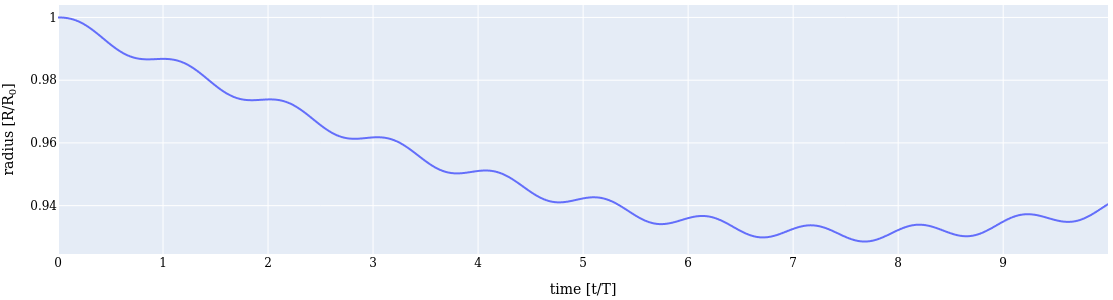

In [27]:
BD_df = pd.DataFrame(
    data={
        "x": time/period,
        "y": BD_obj.R,
        "legend": "bubble radius",
    }
)

fig = px.line(BD_df,x="x", y="y")

fig.update_layout(
    height=300,
    width=1000,
    font=font_dict, 
    margin_l=5, margin_t=5, margin_b=5, margin_r=5,
    xaxis=dict(title="time [t/T]"),
    yaxis=dict(title="radius [R/R<sub>0</sub>]"), #r"$\text{Relative radiated pressure } [p/p_0]$"),
)
fig.show()
if savefig_flag:
    save_figure(fig, f"BD_radius_{result_id}")

## Save results

In [28]:

# Gather db parameters for storage
bd_params = {
    "R_init": R_init,
    "frequency": frequency,
    "pac": pac,
}

bd_params.update(parameters)

additional_params = {
    "raw_data": data,
    "bd_params": bd_params,
    "bubble_radius" : BD_obj.R,
    "bubble_velocity" : BD_obj.Rdot,
    "time" : BD_obj.time
}
additional_params=dict(

)
results.save_data(
    result_id, data_train, tr_obj, centers, labels, 
    sampling_rate, freq_threshold, **additional_params
)

# Plotting

### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

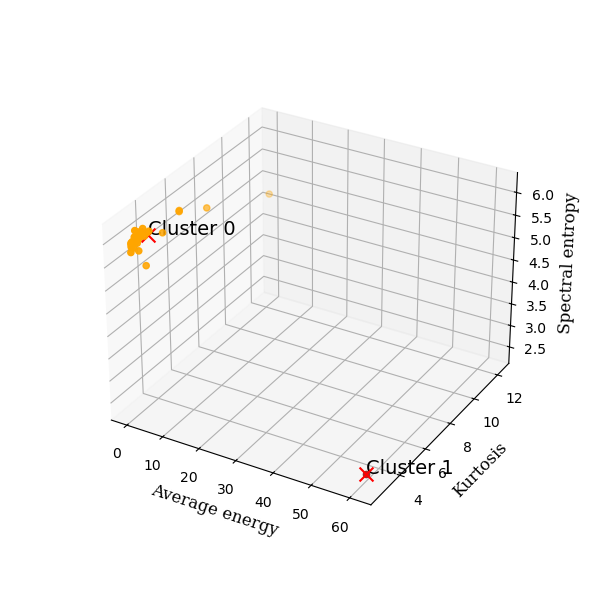

In [29]:
%matplotlib widget
fig = plot.plot_clustering(data_train, centers, labels,metrics_to_plot=classifying_metrics[0:3], 
                           title="",
                           font_dict=font_dict)
if savefig_flag:
    save_figure(fig, f"cluster_centers_{result_id}")

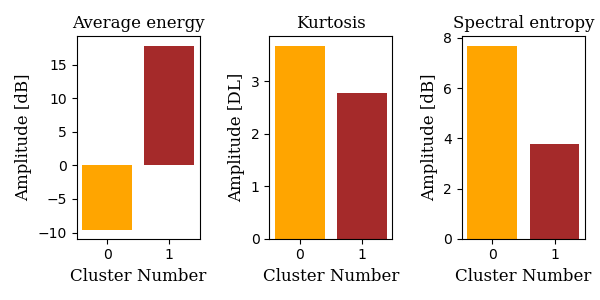

In [30]:
%matplotlib widget

# Plot centroid metrics
xaxis_ticks_labels = {'0':'transient','1':'harmonics'} #dict((i, f"Cluster {i}") for i in range(len(centers)))
label_map = {0:'transient',1:'harmonics'} #dict((i, f"Cluster {i}") for i in range(len(centers)))

fig = plot.plot_centers(classifying_metrics, centers,font_dict=font_dict)#, label_map=xaxis_ticks_labels)

if savefig_flag:
    save_figure(fig, f"sig_components_metrics_{result_id}")

### Results

Plotting the reconstructed waves at each node alongside their assigned group number (non-pca).

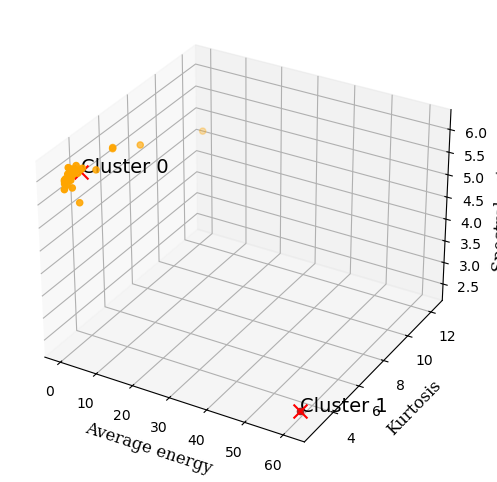

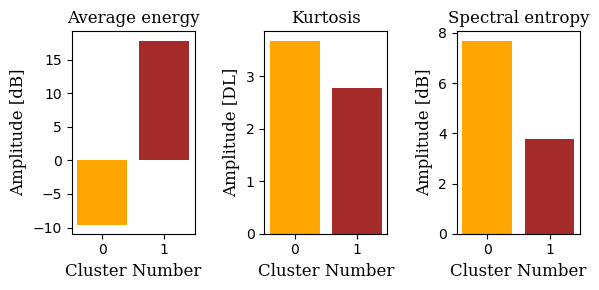

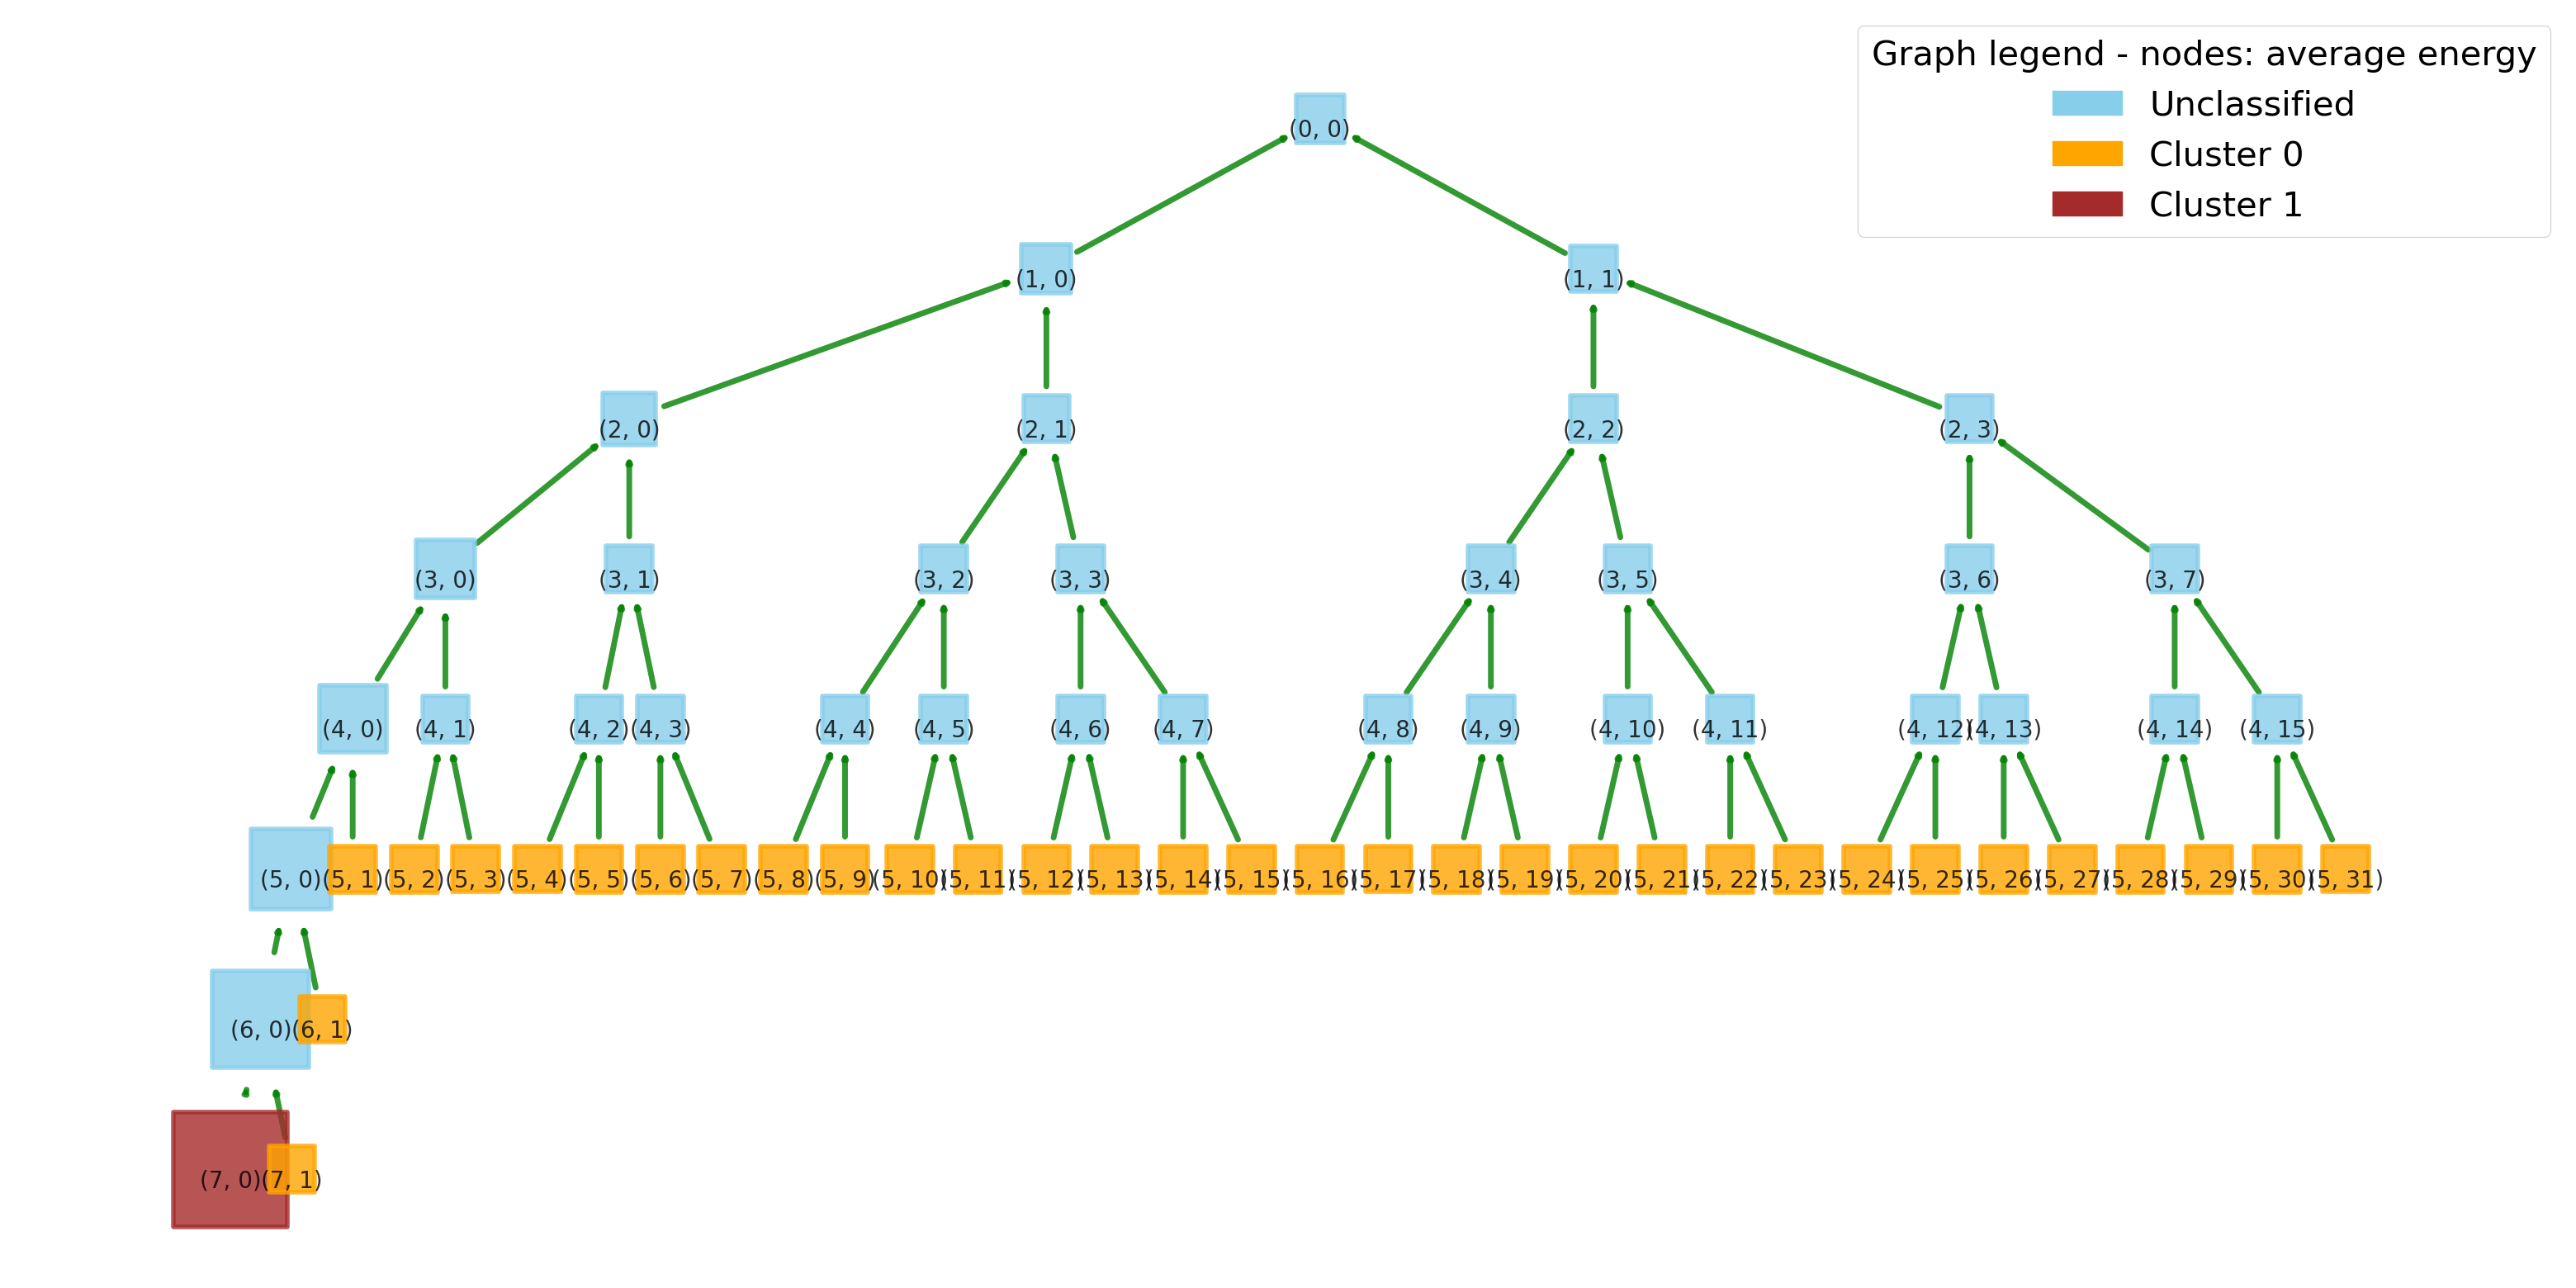

In [31]:
%matplotlib inline
# tr_obj.calc_frequencies(sampling_rate)
# # if tr_obj.max_level() <= 7:

tr_obj.plot_tree(node_size="average energy", node_colour=list(labels), freq_threshold=freq_threshold, 
                 graph_legend="Graph legend - nodes: average energy",fig_name=f"dwpt_graph_{result_id}",
                 display_freq_range_packet = False)


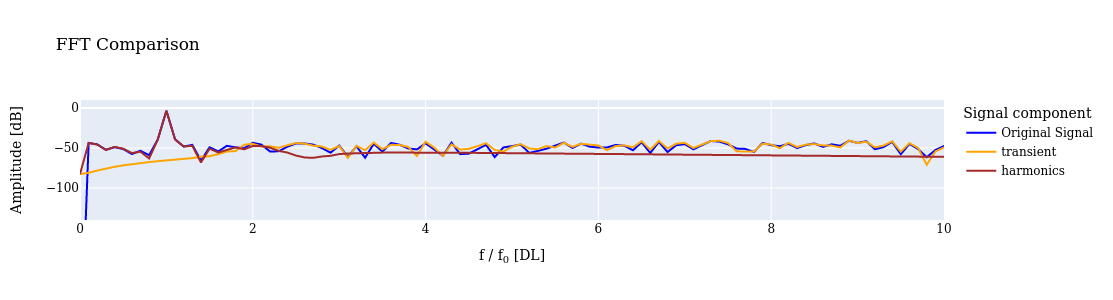

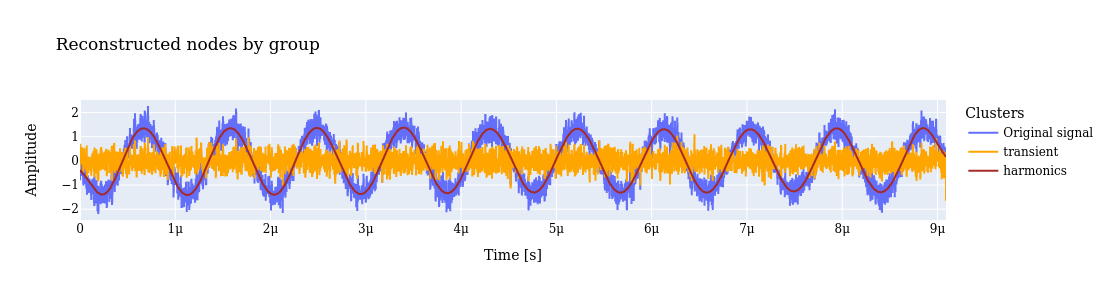

In [32]:
fig = plot.plot_fft_by_group(
    tr_obj, labels, no_clusters=None, sampling_rate=sampling_rate,
    clusters=None, xlim=10, fundamental_freq=frequency,
    freq_threshold=freq_threshold, label_map=label_map,
    font_dict=font_dict,
)
if savefig_flag == True:
    save_figure(fig, f"fft_rec_centers_{result_id}")

fig = plot.plot_reconstructions_by_group(
    tr_obj, labels, no_clusters=None, t_plot=sampling_rate, 
    freq_threshold=freq_threshold, label_map=label_map,
    font_dict=font_dict,
)
if savefig_flag == True:
    save_figure(fig, f"sig_rec_centers_{result_id}")

pca results

In [33]:
# plot pca results
# plot.plot_reconstructions_by_group(tr_obj, labels_pca, no_clusters, t_plot, sampling_rate)

separately plot reconstructions of all nodes belonging to selected clusters

In [34]:
# import wavelet_transform.wpt.inverse_transform as inv
# # Add number to list to plot reconstructions of all nodes belonging to the cluster
# plot_centres = [1]
# for i, (node, assignment) in enumerate(zip(tr_obj.get_leaf_nodes(freq_threshold=freq_threshold), labels)):
#     freq /= frequency
#     if assignment in plot_centres:
#         print("spectral entropy:", node.spectral_entropy)
#         print("crest factor", node.crest_factor)
#         rec = inv.inv_dwpt(tr_obj, node.level, nodes=node)
#         fft_rec, freq = fft(rec, sampling_rate, frequency)
#         plt.plot(freq, np.log10(np.abs(fft_rec)))
#         plt.xlim(0, 5)
#         plt.title(f"frequency range: {node.frequency_range}, fft")
#         plt.show()
#         plt.plot(rec)
#         plt.title(f"reconstructed signal")
#         plt.show()


In [35]:
centers

,average energy,kurtosis,spectral entropy
0,0.110996,3.667687,5.863860
1,61.006970,2.766453,2.388569


In [36]:
# # plot sound wave and fft
# fig = make_subplots(rows=2, cols=1)
# fig.add_trace(
#     go.Scatter(x=t_plot/period , y=data_processed, mode="lines", name="acoustic emission - GA model"), row=1, col=1
# )
# fig.add_trace(
#     go.Scatter(x=psd_freq, y=to_dB(psd_data), 
#                mode="lines", name="fft - amp"),
#     row=2,
#     col=1,
# )
# # fig.add_trace(
# #     go.Scatter(
# #         x=freq, y=np.angle(fft_data, deg=True), mode="lines", name="fft - phase"
# #     ),
# #     row=3,
# #     col=1,
# # )

# fig.update_layout(
#     height=600,
#     width=1000,
#     font=font_dict, 
#     # margin_l=5, margin_t=5, margin_b=5, margin_r=5,
#     xaxis1=dict(title="Time [t/T]"),
#     xaxis2=dict(title="Freq [<i>f/f<sub>0</sub></i>]", range=[0, fft_lim]),
#     # xaxis3=dict(title="Freq [f/f_0]", range=[0, fft_lim]),
#     yaxis1=dict(title="Pressure amplitude [<i>p/p<sub>0</sub></i>]"),
#     yaxis2=dict(title="Amplitude [dB]",range=[-40,40]),
#     # yaxis3=dict(title="Amplitude [rad]"),
# )
# fig.show()
# if savefig_flag:
#     save_figure(fig, f"GA_pressure_{result_id}")